In [1]:
from pathlib import Path

files = list(Path.home().rglob("labels100.csv"))

for file in files:
    print(file)

In [3]:
import pandas as pd
from pathlib import Path

for file in Path("/home/l6feng/private").glob("*.csv"):
    print(file.name)

DSC180A_100labels - categorized - labels100.csv
human_labels.csv
DSC180A_100labels - labels100.csv


In [5]:
import pandas as pd

df = pd.read_csv("/home/l6feng/private/DSC180A_100labels_final_agreed.csv")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFinal category counts:")
print(df["Final Agreed Upon"].value_counts())

print("\nReview status counts:")
print(df["Review Status"].value_counts())

Shape: (100, 12)

Columns: ['row_id', 'memo', 'amount', 'direction', 'Vanessa Categories', 'Aiden Categories', 'Katie Categories', 'Kerim Categories', 'Disagreements', 'Final Agreed Upon', 'Review Status', 'Relabeling Notes']

Final category counts:
Final Agreed Upon
Transfers                        23
Uncertain                        14
Food & Drink                     11
Groceries                        10
Shopping                         10
Subscriptions & Entertainment     9
Gas                               6
Income / Deposits                 4
Cash Out (ATM)                    3
Fees & Adjustments                3
Finance & Investments             2
Debt / Credit Payments            2
Automotive                        1
Travel                            1
Bills & Utilities                 1
Name: count, dtype: int64

Review status counts:
Review Status
Ready     58
Review    42
Name: count, dtype: int64


In [6]:
review = df[df["Review Status"] == "Review"]

print("Rows needing review:", len(review))
print(review["Final Agreed Upon"].value_counts())

display(
    review[
        ["row_id", "Vanessa Categories",
         "Final Agreed Upon", "Relabeling Notes"]
    ]
)

Rows needing review: 42
Final Agreed Upon
Uncertain                        14
Subscriptions & Entertainment     5
Groceries                         5
Gas                               5
Food & Drink                      3
Transfers                         3
Fees & Adjustments                2
Shopping                          2
Travel                            1
Finance & Investments             1
Debt / Credit Payments            1
Name: count, dtype: int64


,row_id,Vanessa Categories,Final Agreed Upon,Relabeling Notes
2,3,Entertainment,Subscriptions & Entertainment,TikTok/Google entertainment purchase; specific...
6,7,Miscellaneous,Uncertain,Generic Google merchant does not specify purch...
7,8,Shopping,Groceries,HARRIS TE appears to indicate Harris Teeter gr...
8,9,Gas,Gas,Amoco gas station may also sell nonfuel items
13,14,Groceries,Groceries,365 Market may be a market/vending transaction...
22,23,Travel,Travel,Uber trip; current taxonomy contains Travel bu...
23,24,Professional Services,Subscriptions & Entertainment,Rocket Money Premium appears to be a paid digi...
25,26,Miscellaneous,Uncertain,MoneyLion descriptor alone does not establish ...
26,27,Groceries,Groceries,365 Market may be vending rather than groceries
27,28,Food & Drink,Uncertain,Aramark serves multiple purchase types; memo a...


In [7]:
fasttext_df = df[["row_id", "memo", "Final Agreed Upon"]].copy()

fasttext_df = fasttext_df.rename(
    columns={"Final Agreed Upon": "label"}
)

print("Total transactions:", len(fasttext_df))
print("\nCategory counts:")
print(fasttext_df["label"].value_counts())

Total transactions: 100

Category counts:
label
Transfers                        23
Uncertain                        14
Food & Drink                     11
Groceries                        10
Shopping                         10
Subscriptions & Entertainment     9
Gas                               6
Income / Deposits                 4
Cash Out (ATM)                    3
Fees & Adjustments                3
Finance & Investments             2
Debt / Credit Payments            2
Automotive                        1
Travel                            1
Bills & Utilities                 1
Name: count, dtype: int64


In [8]:
fasttext_df["cleaned_memo"] = (
    fasttext_df["memo"]
    .fillna("")
    .str.lower()
    .str.split()
    .str.join(" ")
)

print("Empty memos:", (fasttext_df["cleaned_memo"] == "").sum())

print("\nTotal rows:", len(fasttext_df))

Empty memos: 0

Total rows: 100


In [18]:
sample_df = con.execute("""
SELECT
    account_key,
    posted_date,
    TRY_CAST(memo AS VARCHAR) AS memo,
    amount,
    credit_or_debit
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
USING SAMPLE 400 ROWS
""").df()

print("Sample size:", len(sample_df))
print(sample_df.columns.tolist())
print(sample_df["posted_date"].min(), sample_df["posted_date"].max())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sample size: 400
['account_key', 'posted_date', 'memo', 'amount', 'credit_or_debit']
2022-10-30 00:00:00 2026-09-01 00:00:00


In [19]:
sample_df["split"] = "Testing"

sample_df.loc[
    sample_df["posted_date"] < "2026-01-01", "split"
] = "Training"

sample_df.loc[
    (sample_df["posted_date"] >= "2026-01-01") &
    (sample_df["posted_date"] < "2026-07-01"),
    "split"
] = "Validation"

print(sample_df["split"].value_counts())

print("\nUnique accounts per split:")
print(sample_df.groupby("split")["account_key"].nunique())

split
Training      195
Validation    175
Testing        30
Name: count, dtype: int64

Unique accounts per split:
split
Testing        29
Training      194
Validation    161
Name: account_key, dtype: int64


In [20]:
account_splits = sample_df.groupby("account_key")["split"].nunique()

print("Accounts in multiple splits:", (account_splits > 1).sum())

print("Accounts in only one split:", (account_splits == 1).sum())

print("Total unique accounts:", len(account_splits))

Accounts in multiple splits: 1
Accounts in only one split: 381
Total unique accounts: 382


In [21]:
con.execute("""
DESCRIBE SELECT *
FROM read_parquet('/home/l6feng/teams/d12/tx_account_summary.parquet')
""").df()

,column_name,column_type,null,key,default,extra
0,account_key,UINTEGER,YES,None,None,None
1,n_tx,BIGINT,YES,None,None,None
2,first_tx,TIMESTAMP,YES,None,None,None
3,last_tx,TIMESTAMP,YES,None,None,None


In [22]:
accounts_df = con.execute("""
SELECT
    account_key,
    n_tx,
    first_tx,
    last_tx
FROM read_parquet('/home/l6feng/teams/d12/tx_account_summary.parquet')
WHERE n_tx >= 100
    AND first_tx < '2026-01-01'
    AND last_tx >= '2026-07-01'
ORDER BY n_tx DESC
LIMIT 20
""").df()

print("Candidate accounts:", len(accounts_df))
display(accounts_df)

Candidate accounts: 20


,account_key,n_tx,first_tx,last_tx
0,207405,76789078,2023-12-30,2026-09-23
1,786229,251576,2025-12-31,2026-07-30
2,366192,222158,2025-12-28,2026-09-20
3,750261,161696,2025-12-25,2026-09-18
4,24533,157375,2025-12-28,2026-09-19
5,634367,140831,2025-12-29,2026-07-29
6,143276,136220,2025-12-29,2026-07-29
7,384455,132781,2025-12-28,2026-07-06
8,441958,116332,2025-12-28,2026-09-14
9,470649,112226,2024-07-25,2026-07-05


In [23]:
accounts_df = con.execute("""
SELECT
    account_key,
    n_tx,
    first_tx,
    last_tx
FROM read_parquet('/home/l6feng/teams/d12/tx_account_summary.parquet')
WHERE n_tx BETWEEN 100 AND 5000
    AND first_tx < '2025-07-01'
    AND last_tx >= '2026-07-01'
ORDER BY RANDOM()
LIMIT 20
""").df()

print("Candidate accounts:", len(accounts_df))
display(accounts_df)

Candidate accounts: 20


,account_key,n_tx,first_tx,last_tx
0,711122,127,2025-06-02,2026-08-17
1,497277,3878,2025-06-27,2026-07-24
2,852224,4190,2025-06-05,2026-08-18
3,352969,1240,2025-06-10,2026-07-02
4,365470,266,2025-06-16,2026-09-20
5,776414,2781,2025-03-07,2026-09-17
6,671014,850,2025-06-25,2026-09-13
7,859844,3006,2025-05-01,2026-07-17
8,515129,3411,2025-05-15,2026-09-10
9,551093,2710,2025-06-26,2026-07-07


### Q1

In [12]:
import duckdb

con = duckdb.connect()

con.execute("""
SELECT
    COUNT(*) AS total_transactions,
    COUNT(DISTINCT account_key) AS unique_accounts,
    MIN(posted_date) AS earliest_date,
    MAX(posted_date) AS latest_date
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_transactions,unique_accounts,earliest_date,latest_date
0,2017117849,1052849,2022-01-27,2026-09-23


In [13]:
con.execute("""
SELECT
    YEAR(posted_date) AS year,
    COUNT(*) AS transactions,
    COUNT(DISTINCT account_key) AS unique_accounts
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
GROUP BY YEAR(posted_date)
ORDER BY year
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,year,transactions,unique_accounts
0,2022,2660958,6743
1,2023,22053029,36017
2,2024,169046214,127460
3,2025,726875616,774251
4,2026,1096482032,783682


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

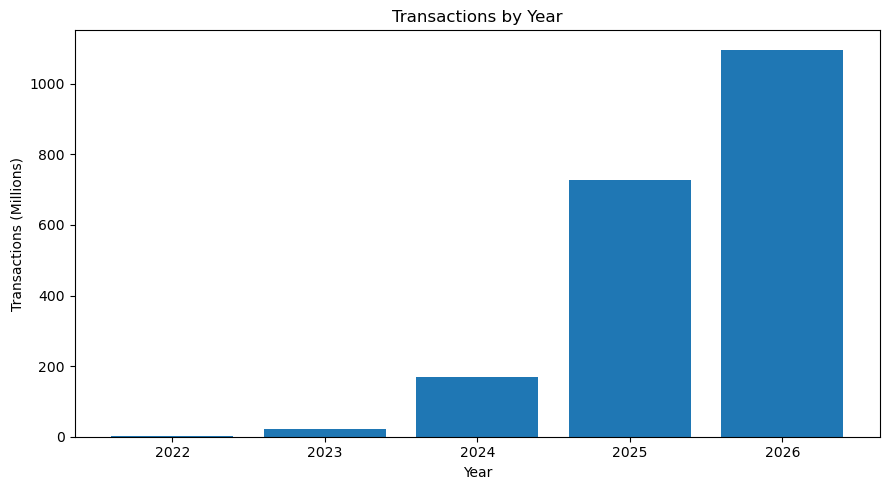

In [14]:
import matplotlib.pyplot as plt

df_year = con.execute("""
SELECT
    YEAR(posted_date) AS year,
    COUNT(*) AS transactions
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
GROUP BY YEAR(posted_date)
ORDER BY year
""").df()

plt.figure(figsize=(9, 5))
plt.bar(df_year["year"].astype(str), df_year["transactions"] / 1e6)

plt.title("Transactions by Year")
plt.xlabel("Year")
plt.ylabel("Transactions (Millions)")

plt.tight_layout()
plt.show()

In [15]:
con.execute("""
WITH accounts_by_year AS (
    SELECT DISTINCT
        account_key,
        YEAR(posted_date) AS year
    FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
    WHERE YEAR(posted_date) IN (2025, 2026)
)
SELECT
    COUNT(DISTINCT CASE WHEN year = 2025 THEN account_key END) AS accounts_2025,
    COUNT(DISTINCT CASE WHEN year = 2026 THEN account_key END) AS accounts_2026,
    COUNT(DISTINCT CASE WHEN year = 2025 AND account_key IN (
        SELECT account_key FROM accounts_by_year WHERE year = 2026
    ) THEN account_key END) AS accounts_in_both_years
FROM accounts_by_year
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,accounts_2025,accounts_2026,accounts_in_both_years
0,774251,783682,537721


In [16]:
con.execute("""
DESCRIBE SELECT *
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_01_of_15.parquet')
""").df()

,column_name,column_type,null,key,default,extra
0,account_key,UINTEGER,YES,None,None,None
1,amount,"DECIMAL(18,2)",YES,None,None,None
2,credit_or_debit,TINYINT,YES,None,None,None
3,posted_date,DATE,YES,None,None,None
4,memo,BLOB,YES,None,None,None


In [17]:
con.execute("""
SELECT
    CASE
        WHEN posted_date < '2026-01-01' THEN 'Training'
        WHEN posted_date < '2026-07-01' THEN 'Validation'
        ELSE 'Testing'
    END AS split,
    COUNT(*) AS transactions,
    COUNT(DISTINCT account_key) AS accounts
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
GROUP BY split
ORDER BY split
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,split,transactions,accounts
0,Testing,160440879,284968
1,Training,920635817,806892
2,Validation,936041153,779435


In [24]:
con.execute("""
SELECT
    COUNT(*) AS accounts_active_in_test,
    COUNT(CASE WHEN first_tx >= '2026-07-01'
        THEN 1 END) AS newly_observed_accounts,
    COUNT(CASE WHEN first_tx < '2026-07-01'
        THEN 1 END) AS previously_observed_accounts
FROM read_parquet('/home/l6feng/teams/d12/tx_account_summary.parquet')
WHERE last_tx >= '2026-07-01'
""").df()

,accounts_active_in_test,newly_observed_accounts,previously_observed_accounts
0,284968,4141,280827


In [25]:
new_accounts_df = con.execute("""
SELECT
    DATE_TRUNC('month', first_tx) AS month,
    COUNT(*) AS new_accounts
FROM read_parquet('/home/l6feng/teams/d12/tx_account_summary.parquet')
WHERE first_tx IS NOT NULL
GROUP BY DATE_TRUNC('month', first_tx)
ORDER BY month
""").df()

display(new_accounts_df)

,month,new_accounts
0,2022-01-01,1
1,2022-05-01,1
2,2022-06-01,473
3,2022-07-01,1101
4,2022-08-01,1438
5,2022-09-01,1849
6,2022-10-01,1106
7,2022-11-01,305
8,2022-12-01,469
9,2023-01-01,1230


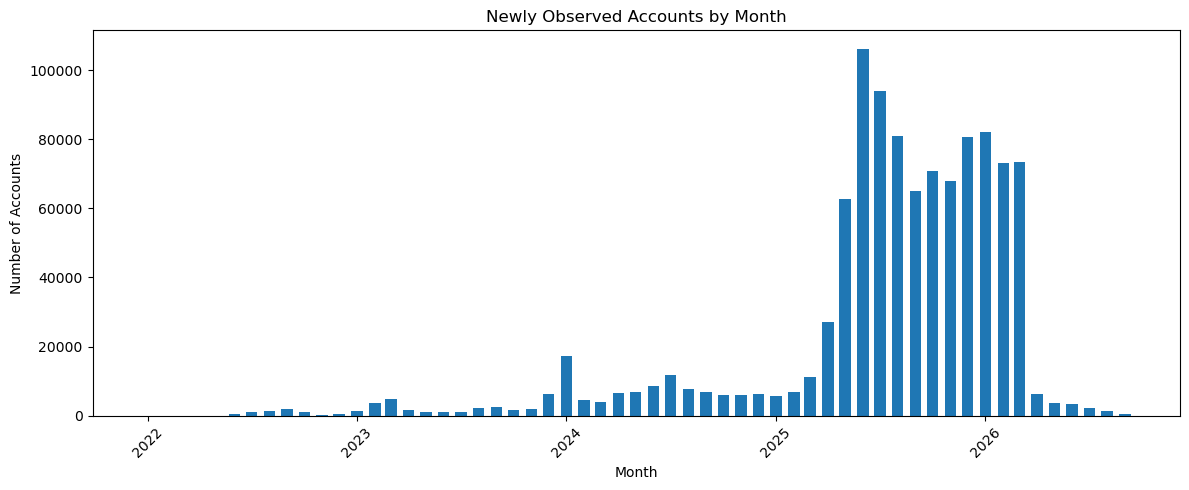

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    new_accounts_df["month"],
    new_accounts_df["new_accounts"],
    width=20
)

plt.title("Newly Observed Accounts by Month")
plt.xlabel("Month")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

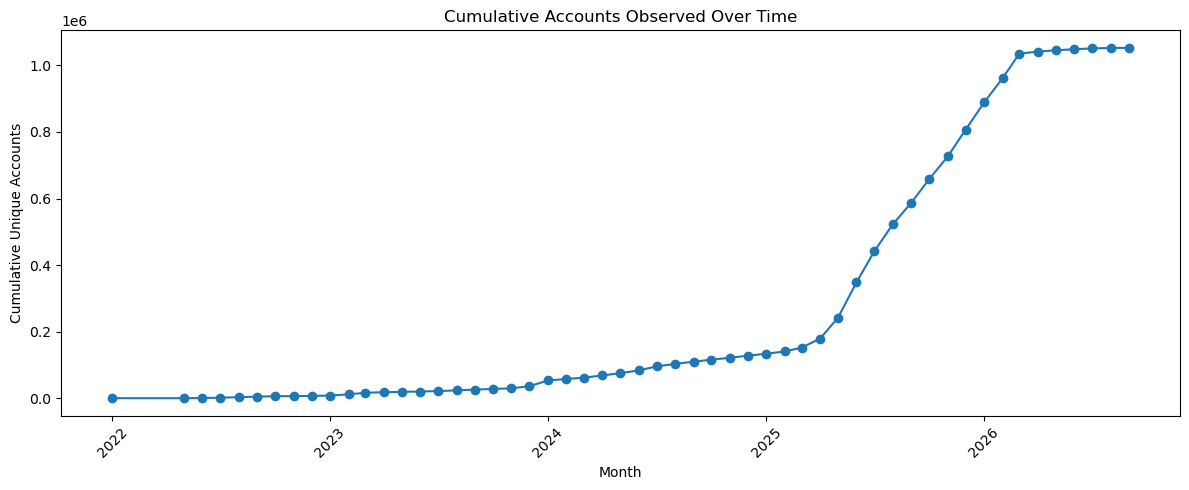

In [27]:
new_accounts_df["cumulative_accounts"] = (
    new_accounts_df["new_accounts"].cumsum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    new_accounts_df["month"],
    new_accounts_df["cumulative_accounts"],
    marker="o"
)

plt.title("Cumulative Accounts Observed Over Time")
plt.xlabel("Month")
plt.ylabel("Cumulative Unique Accounts")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [29]:
con.register("candidate_accounts", accounts_df[["account_key"]])

period_counts = con.execute("""
SELECT
    t.account_key,
    COUNT(CASE WHEN t.posted_date < '2026-01-01' THEN 1 END) AS training,
    COUNT(CASE WHEN t.posted_date >= '2026-01-01'
                AND t.posted_date < '2026-07-01' THEN 1 END) AS validation,
    COUNT(CASE WHEN t.posted_date >= '2026-07-01' THEN 1 END) AS testing
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet') t
JOIN candidate_accounts a
    ON t.account_key = a.account_key
GROUP BY t.account_key
ORDER BY t.account_key
""").df()

display(period_counts)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,account_key,training,validation,testing
0,47304,2538,1214,44
1,78574,613,942,86
2,119459,869,988,102
3,152673,1556,2856,321
4,240266,1667,2595,311
5,352969,394,834,12
6,365470,123,75,68
7,497277,2525,1291,62
8,515129,1391,1801,219
9,551093,740,1844,126


In [30]:
import numpy as np

rng = np.random.default_rng(42)

account_ids = period_counts["account_key"].to_numpy().copy()
rng.shuffle(account_ids)

seen_accounts = account_ids[:16]
heldout_accounts = account_ids[16:]

print("Seen accounts:", len(seen_accounts))
print("Held-out accounts:", len(heldout_accounts))

print("\nAccount overlap:",
      len(set(seen_accounts) & set(heldout_accounts)))

Seen accounts: 16
Held-out accounts: 4

Account overlap: 0


In [ ]:
import pandas as pd

con.register(
    "seen_accounts_df",
    pd.DataFrame({"account_key": seen_accounts})
)

con.register(
    "heldout_accounts_df",
    pd.DataFrame({"account_key": heldout_accounts})
)

sample400 = con.execute("""
WITH transactions AS (
    SELECT
        account_key,
        posted_date,
        TRY_CAST(memo AS VARCHAR) AS memo,
        amount,
        credit_or_debit
    FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
),
sampled AS (
    SELECT *,
        ROW_NUMBER() OVER (
            PARTITION BY split
            ORDER BY RANDOM()
        ) AS rn
    FROM (
        SELECT t.*, 'Training' AS split
        FROM transactions t
        JOIN seen_accounts_df a USING (account_key)
        WHERE posted_date < '2026-01-01'

        UNION ALL

        SELECT t.*, 'Validation' AS split
        FROM transactions t
        JOIN seen_accounts_df a USING (account_key)
        WHERE posted_date >= '2026-01-01'
          AND posted_date < '2026-07-01'

        UNION ALL

        SELECT t.*, 'Testing A' AS split
        FROM transactions t
        JOIN seen_accounts_df a USING (account_key)
        WHERE posted_date >= '2026-07-01'

        UNION ALL

        SELECT t.*, 'Testing B' AS split
        FROM transactions t
        JOIN heldout_accounts_df a USING (account_key)
        WHERE posted_date >= '2026-07-01'
    )
)
SELECT
    account_key,
    posted_date,
    memo,
    amount,
    credit_or_debit,
    split
FROM sampled
WHERE
    (split = 'Training' AND rn <= 280)
    OR (split = 'Validation' AND rn <= 60)
    OR (split = 'Testing A' AND rn <= 30)
    OR (split = 'Testing B' AND rn <= 30)
""").df()

print(sample400["split"].value_counts())
print("\nTotal:", len(sample400))

In [ ]:
con.close()

import duckdb
con = duckdb.connect()

In [4]:
import pandas as pd

con.register(
    "seen_accounts_df",
    pd.DataFrame({"account_key": seen_accounts})
)

con.register(
    "heldout_accounts_df",
    pd.DataFrame({"account_key": heldout_accounts})
)

path = "/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet"

def get_sample(accounts, condition, n, split):
    result = con.execute(f"""
        SELECT
            t.account_key,
            t.posted_date,
            TRY_CAST(t.memo AS VARCHAR) AS memo,
            t.amount,
            t.credit_or_debit
        FROM read_parquet('{path}') t
        JOIN {accounts} a USING (account_key)
        WHERE {condition}
        USING SAMPLE {n} ROWS
    """).df()

    result["split"] = split
    return result

train = get_sample(
    "seen_accounts_df",
    "posted_date < '2026-01-01'",
    280,
    "Training"
)

valid = get_sample(
    "seen_accounts_df",
    "posted_date >= '2026-01-01' AND posted_date < '2026-07-01'",
    60,
    "Validation"
)

test_a = get_sample(
    "seen_accounts_df",
    "posted_date >= '2026-07-01'",
    30,
    "Testing A"
)

test_b = get_sample(
    "heldout_accounts_df",
    "posted_date >= '2026-07-01'",
    30,
    "Testing B"
)

sample400 = pd.concat(
    [train, valid, test_a, test_b],
    ignore_index=True
)

print(sample400["split"].value_counts())
print("\nTotal:", len(sample400))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

split
Training      127
Validation     21
Name: count, dtype: int64

Total: 148


In [1]:
from pathlib import Path

temp = Path(".tmp")

print("Temporary folder exists:", temp.exists())

if temp.exists():
    for file in temp.glob("duckdb_temp_storage*"):
        print(file.name, round(file.stat().st_size / 1e6, 2), "MB")

Temporary folder exists: False


In [2]:
import duckdb
import pandas as pd
import numpy as np

con = duckdb.connect()

account_ids = [
    47304, 78574, 119459, 152673, 240266,
    352969, 365470, 497277, 515129, 551093,
    660021, 671014, 688479, 711122, 762078,
    776414, 852224, 859844, 947219, 978312
]

rng = np.random.default_rng(42)
account_ids = np.array(account_ids)
rng.shuffle(account_ids)

seen_accounts = account_ids[:16]
heldout_accounts = account_ids[16:]

print("Seen accounts:", len(seen_accounts))
print("Held-out accounts:", len(heldout_accounts))
print("Overlap:", len(set(seen_accounts) & set(heldout_accounts)))

Seen accounts: 16
Held-out accounts: 4
Overlap: 0


In [3]:
import pandas as pd

path = "/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet"

account_list = ", ".join(str(x) for x in account_ids)

selected_df = con.execute(f"""
SELECT
    account_key,
    posted_date,
    TRY_CAST(memo AS VARCHAR) AS memo,
    amount,
    credit_or_debit
FROM read_parquet('{path}')
WHERE account_key IN ({account_list})
""").df()

print("Transactions retrieved:", len(selected_df))
print("Unique accounts:", selected_df["account_key"].nunique())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Transactions retrieved: 48466
Unique accounts: 20


In [8]:
import numpy as np
import pandas as pd

selected_df["posted_date"] = pd.to_datetime(selected_df["posted_date"])

seen_df = selected_df[selected_df["account_key"].isin(seen_accounts)]
heldout_df = selected_df[selected_df["account_key"].isin(heldout_accounts)]

train = seen_df[seen_df["posted_date"] < "2026-01-01"].sample(
    n=280, random_state=42
)

valid = seen_df[
    (seen_df["posted_date"] >= "2026-01-01") &
    (seen_df["posted_date"] < "2026-07-01")
].sample(n=60, random_state=42)

test_a = seen_df[seen_df["posted_date"] >= "2026-07-01"].sample(
    n=30, random_state=42
)

test_b = heldout_df[heldout_df["posted_date"] >= "2026-07-01"].sample(
    n=30, random_state=42
)

train = train.assign(split="Training")
valid = valid.assign(split="Validation")
test_a = test_a.assign(split="Testing A")
test_b = test_b.assign(split="Testing B")

sample400 = pd.concat(
    [train, valid, test_a, test_b],
    ignore_index=True
)

print(sample400["split"].value_counts())
print("\nTotal:", len(sample400))

split
Training      280
Validation     60
Testing A      30
Testing B      30
Name: count, dtype: int64

Total: 400


In [9]:
sample400 = pd.concat(
    [
        train.assign(split="Training"),
        valid.assign(split="Validation"),
        test_a.assign(split="Testing A"),
        test_b.assign(split="Testing B")
    ],
    ignore_index=True
)

print(sample400["split"].value_counts())
print("\nTotal:", len(sample400))

split
Training      280
Validation     60
Testing A      30
Testing B      30
Name: count, dtype: int64

Total: 400


In [10]:
print("Total rows:", len(sample400))

print("\nTransactions by split:")
print(sample400["split"].value_counts())

print("\nUnique accounts by split:")
print(sample400.groupby("split")["account_key"].nunique())

print("\nMissing memos:")
print(sample400["memo"].isna().sum())

print("\nDuplicate rows:")
print(sample400.duplicated(
    subset=["account_key", "posted_date", "memo", "amount", "credit_or_debit"]
).sum())

print("\nSeen accounts represented in training:")
print(train["account_key"].nunique())

print("\nTesting A accounts also in training:")
print(len(set(test_a["account_key"]) & set(train["account_key"])))

print("\nTesting B accounts also in training:")
print(len(set(test_b["account_key"]) & set(train["account_key"])))

Total rows: 400

Transactions by split:
split
Training      280
Validation     60
Testing A      30
Testing B      30
Name: count, dtype: int64

Unique accounts by split:
split
Testing A     11
Testing B      4
Training      16
Validation    13
Name: account_key, dtype: int64

Missing memos:
0

Duplicate rows:
9

Seen accounts represented in training:
16

Testing A accounts also in training:
11

Testing B accounts also in training:
0


In [11]:
cols = [
    "account_key",
    "posted_date",
    "memo",
    "amount",
    "credit_or_debit"
]

print("Duplicates within each split:")
print(
    sample400.groupby("split")
    .apply(lambda x: x.duplicated(subset=cols).sum())
)

print("\nDuplicate rows across the full sample:")
print(sample400.duplicated(subset=cols).sum())

Duplicates within each split:
split
Testing A     0
Testing B     0
Training      8
Validation    1
dtype: int64

Duplicate rows across the full sample:
9


/tmp/ipykernel_1187/4268137019.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.duplicated(subset=cols).sum())


In [12]:
cols = ["account_key", "posted_date", "memo", "amount", "credit_or_debit"]

sample400 = sample400.drop_duplicates(subset=cols).copy()

print("Rows after removing duplicates:", len(sample400))
print(sample400["split"].value_counts())

Rows after removing duplicates: 391
split
Training      272
Validation     59
Testing A      30
Testing B      30
Name: count, dtype: int64


In [13]:
cols = ["account_key", "posted_date", "memo", "amount", "credit_or_debit"]

available = selected_df.drop_duplicates(subset=cols).copy()

available = available.merge(
    sample400[cols],
    on=cols,
    how="left",
    indicator=True
)

available = available[available["_merge"] == "left_only"].drop(
    columns="_merge"
)

train_pool = available[
    available["account_key"].isin(seen_accounts) &
    (available["posted_date"] < "2026-01-01")
]

valid_pool = available[
    available["account_key"].isin(seen_accounts) &
    (available["posted_date"] >= "2026-01-01") &
    (available["posted_date"] < "2026-07-01")
]

new_train = train_pool.sample(n=8, random_state=42).assign(split="Training")
new_valid = valid_pool.sample(n=1, random_state=42).assign(split="Validation")

sample400 = pd.concat(
    [sample400, new_train, new_valid],
    ignore_index=True
)

print(sample400["split"].value_counts())
print("\nTotal:", len(sample400))
print("Duplicate rows:", sample400.duplicated(subset=cols).sum())

split
Training      280
Validation     60
Testing A      30
Testing B      30
Name: count, dtype: int64

Total: 400
Duplicate rows: 0


In [14]:
sample400["Final Agreed Upon"] = ""
sample400["Review Status"] = ""

sample400.to_csv(
    "/home/l6feng/private/fasttext_400_to_label.csv",
    index=False
)

print("CSV saved successfully")
print("Rows:", len(sample400))

CSV saved successfully
Rows: 400


In [15]:
import pandas as pd

df400 = pd.read_csv("/home/l6feng/private/fasttext_400_labeled_proposed.csv")

print("Shape:", df400.shape)
print("\nColumns:", df400.columns.tolist())

print("\nTransactions by split:")
print(df400["split"].value_counts())

print("\nCategory counts:")
print(df400["Final Agreed Upon"].value_counts())

print("\nMissing labels:")
print(df400["Final Agreed Upon"].isna().sum())

Shape: (400, 9)

Columns: ['account_key', 'posted_date', 'memo', 'amount', 'credit_or_debit', 'split', 'Final Agreed Upon', 'Review Status', 'Relabeling Notes']

Transactions by split:
split
Training      280
Validation     60
Testing A      30
Testing B      30
Name: count, dtype: int64

Category counts:
Final Agreed Upon
Transfers                        91
Uncertain                        38
Subscriptions & Entertainment    38
Income / Deposits                37
Food & Drink                     33
Shopping                         31
Groceries                        25
Finance & Investments            24
Gas                              23
Debt / Credit Payments           17
Fees & Adjustments               13
Bills & Utilities                11
Cash Out (ATM)                    5
Travel                            4
Professional Services             3
Miscellaneous                     2
Health & Wellness                 2
Automotive                        2
Gifts & Donations          

In [16]:
category_counts = pd.crosstab(
    df400["Final Agreed Upon"],
    df400["split"]
)

print(category_counts.to_string())

print("\nCategories missing from training:")
print(category_counts[category_counts["Training"] == 0].index.tolist())

print("\nReview status by split:")
print(pd.crosstab(df400["split"], df400["Review Status"]))

split                          Testing A  Testing B  Training  Validation
Final Agreed Upon                                                        
Automotive                             1          0         1           0
Bills & Utilities                      1          1         7           2
Cash Out (ATM)                         0          1         3           1
Debt / Credit Payments                 4          1        10           2
Fees & Adjustments                     0          0        12           1
Finance & Investments                  8          3        12           1
Food & Drink                           0          3        22           8
Gas                                    0          2        16           5
Gifts & Donations                      0          0         1           0
Groceries                              2          1        20           2
Health & Wellness                      0          0         1           1
Income / Deposits                     

In [17]:
import re

label_map = {
    label: re.sub(r"[^a-z0-9]+", "_", label.lower()).strip("_")
    for label in df400["Final Agreed Upon"].unique()
}

df400["label_id"] = df400["Final Agreed Upon"].map(label_map)

df400["cleaned_memo"] = (
    df400["memo"]
    .fillna("")
    .str.lower()
    .str.split()
    .str.join(" ")
)

def save_fasttext(data, filename):
    with open(filename, "w") as f:
        for _, row in data.iterrows():
            if row["cleaned_memo"]:
                f.write(
                    "__label__" + row["label_id"] + " " +
                    row["cleaned_memo"] + "\n"
                )

save_fasttext(df400[df400["split"] == "Training"], "train.txt")
save_fasttext(df400[df400["split"] == "Validation"], "valid.txt")
save_fasttext(df400[df400["split"] == "Testing A"], "test_a.txt")
save_fasttext(df400[df400["split"] == "Testing B"], "test_b.txt")

print("FastText files created.")
print("\nLabel mapping:")
print(label_map)

FastText files created.

Label mapping:
{'Gas': 'gas', 'Fees & Adjustments': 'fees_adjustments', 'Uncertain': 'uncertain', 'Groceries': 'groceries', 'Shopping': 'shopping', 'Transfers': 'transfers', 'Debt / Credit Payments': 'debt_credit_payments', 'Subscriptions & Entertainment': 'subscriptions_entertainment', 'Finance & Investments': 'finance_investments', 'Income / Deposits': 'income_deposits', 'Professional Services': 'professional_services', 'Bills & Utilities': 'bills_utilities', 'Food & Drink': 'food_drink', 'Cash Out (ATM)': 'cash_out_atm', 'Gifts & Donations': 'gifts_donations', 'Miscellaneous': 'miscellaneous', 'Travel': 'travel', 'Health & Wellness': 'health_wellness', 'Automotive': 'automotive'}


In [ ]:
%pip install fasttext

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 5.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.1.0-py3-none-any.whl.metadata (10 kB)
Using cached pybind11-3.1.0-py3-none-any.whl (319 kB)

In [25]:
import fasttext

model = fasttext.train_supervised(
    input="train.txt",
    wordNgrams=2
)

n, p1, r1 = model.test("valid.txt")

print("Validation examples:", n)
print("Precision:", p1)
print("Recall:", r1)

model.save_model("expense.bin")

Read 0M words
Number of words:  531
Number of labels: 19


Validation examples: 60
Precision: 0.06666666666666667
Recall: 0.06666666666666667


Progress: 100.0% words/sec/thread:     715 lr:  0.000000 avg.loss:  2.947536 ETA:   0h 0m 0s


In [21]:
valid_df = df400[df400["split"] == "Validation"].copy()

pred_labels, scores = model.predict(
    valid_df["cleaned_memo"].tolist(),
    k=1
)

valid_df["predicted"] = [
    label[0].replace("__label__", "")
    for label in pred_labels
]

valid_df["actual"] = valid_df["label_id"]
valid_df["correct"] = valid_df["predicted"] == valid_df["actual"]

print("Correct predictions:", valid_df["correct"].sum())
print("Total validation transactions:", len(valid_df))

print("\nActual vs predicted categories:")
print(pd.crosstab(valid_df["actual"], valid_df["predicted"]))

print("\nCorrect predictions by category:")
print(
    valid_df.groupby("actual")["correct"]
    .agg(["sum", "count"])
)

Correct predictions: 4
Total validation transactions: 60

Actual vs predicted categories:
predicted                    income_deposits
actual                                      
bills_utilities                            2
cash_out_atm                               1
debt_credit_payments                       2
fees_adjustments                           1
finance_investments                        1
food_drink                                 8
gas                                        5
groceries                                  2
health_wellness                            1
income_deposits                            4
shopping                                   5
subscriptions_entertainment                4
transfers                                 17
travel                                     1
uncertain                                  6

Correct predictions by category:
                             sum  count
actual                                 
bills_utilities                

In [22]:
memos = valid_df["cleaned_memo"].tolist()[:10]

pred_labels, scores = model.predict(memos, k=2)

for i in range(len(memos)):
    print("Actual:", valid_df.iloc[i]["actual"])
    print("Predicted:", pred_labels[i])
    print("Scores:", scores[i])
    print()

Actual: food_drink
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.10262257 0.06529345]

Actual: groceries
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.07884638 0.06019565]

Actual: gas
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.18972738 0.0765334 ]

Actual: subscriptions_entertainment
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.3257602  0.08237244]

Actual: transfers
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.1152946  0.06948788]

Actual: gas
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.19121198 0.0768697 ]

Actual: shopping
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.19089903 0.07681949]

Actual: uncertain
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [0.08842734 0.06246952]

Actual: food_drink
Predicted: ['__label__income_deposits', '__label__transfers']
Scores: [

In [23]:
n_train, p_train, r_train = model.test("train.txt")

print("Training examples:", n_train)
print("Training precision:", p_train)
print("Training recall:", r_train)

print("\nValidation examples:", n)
print("Validation precision:", p1)
print("Validation recall:", r1)

Training examples: 280
Training precision: 0.08928571428571429
Training recall: 0.08928571428571429

Validation examples: 60
Validation precision: 0.06666666666666667
Validation recall: 0.06666666666666667


In [24]:
print(model.get_args())

AttributeError: '_FastText' object has no attribute 'get_args'

In [26]:
print("Epochs:", model.f.getArgs().epoch)

Epochs: 5


In [27]:
args = model.f.getArgs()

print("Epochs:", args.epoch)
print("Learning rate:", args.lr)
print("Word n-grams:", args.wordNgrams)
print("Minimum word count:", args.minCount)
print("Dimensions:", args.dim)

Epochs: 5
Learning rate: 0.1
Word n-grams: 2
Minimum word count: 1
Dimensions: 100


In [28]:
model25 = fasttext.train_supervised(
    input="train.txt",
    wordNgrams=2,
    epoch=25
)

n25_train, p25_train, r25_train = model25.test("train.txt")
n25_valid, p25_valid, r25_valid = model25.test("valid.txt")

print("Training accuracy:", p25_train)
print("Validation accuracy:", p25_valid)

Read 0M words
Number of words:  531
Number of labels: 19


Training accuracy: 0.6321428571428571
Validation accuracy: 0.4166666666666667


Progress: 100.0% words/sec/thread:    1923 lr:  0.000000 avg.loss:  2.304787 ETA:   0h 0m 0s


In [29]:
valid_df = df400[df400["split"] == "Validation"].copy()

pred_labels, scores = model25.predict(
    valid_df["cleaned_memo"].tolist(),
    k=1
)

valid_df["predicted"] = [
    label[0].replace("__label__", "")
    for label in pred_labels
]

valid_df["actual"] = valid_df["label_id"]
valid_df["correct"] = valid_df["predicted"] == valid_df["actual"]

print("Correct predictions:", valid_df["correct"].sum())
print("Total transactions:", len(valid_df))

print("\nCorrect predictions by category:")
print(valid_df.groupby("actual")["correct"].agg(["sum", "count"]))

print("\nActual vs. predicted:")
print(pd.crosstab(valid_df["actual"], valid_df["predicted"]))

Correct predictions: 25
Total transactions: 60

Correct predictions by category:
                             sum  count
actual                                 
bills_utilities                0      2
cash_out_atm                   0      1
debt_credit_payments           0      2
fees_adjustments               0      1
finance_investments            0      1
food_drink                     6      8
gas                            0      5
groceries                      0      2
health_wellness                0      1
income_deposits                3      4
shopping                       4      5
subscriptions_entertainment    2      4
transfers                     10     17
travel                         0      1
uncertain                      0      6

Actual vs. predicted:
predicted                    finance_investments  food_drink  income_deposits  \
actual                                                                          
bills_utilities                                1      

In [30]:
results = []

for epoch in [5, 25, 50, 100]:
    m = fasttext.train_supervised(
        input="train.txt",
        wordNgrams=2,
        epoch=epoch
    )

    _, train_acc, _ = m.test("train.txt")
    _, valid_acc, _ = m.test("valid.txt")

    results.append({
        "Epochs": epoch,
        "Training Accuracy": train_acc,
        "Validation Accuracy": valid_acc
    })

results_df = pd.DataFrame(results)

display(results_df)

Read 0M words
Number of words:  531
Number of labels: 19
Progress: 100.0% words/sec/thread:     695 lr:  0.000000 avg.loss:  2.892668 ETA:   0h 0m 0s
Read 0M words
Number of words:  531
Number of labels: 19
Progress: 100.0% words/sec/thread:    2984 lr:  0.000000 avg.loss:  2.197936 ETA:   0h 0m 0s
Read 0M words
Number of words:  531
Number of labels: 19
Progress: 100.0% words/sec/thread:    2250 lr:  0.000000 avg.loss:  1.767606 ETA:   0h 0m 0s
Read 0M words
Number of words:  531
Number of labels: 19
Progress: 100.0% words/sec/thread:    3636 lr:  0.000000 avg.loss:  0.764525 ETA:   0h 0m 0s


,Epochs,Training Accuracy,Validation Accuracy
0,5,0.089286,0.066667
1,25,0.639286,0.416667
2,50,0.925000,0.650000
3,100,0.953571,0.616667


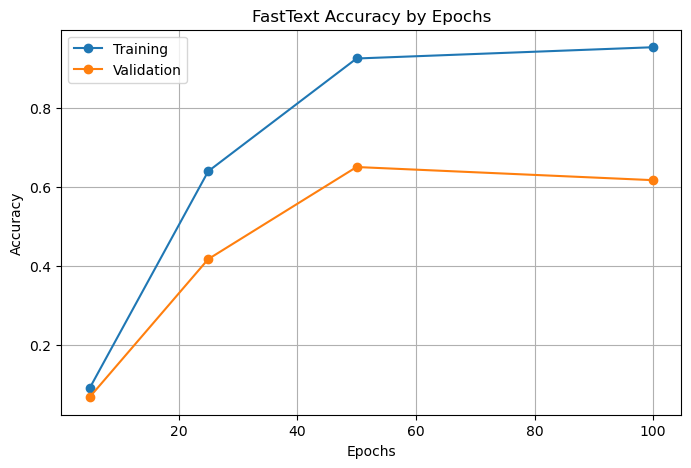

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Epochs"],
    results_df["Training Accuracy"],
    marker="o",
    label="Training"
)

plt.plot(
    results_df["Epochs"],
    results_df["Validation Accuracy"],
    marker="o",
    label="Validation"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("FastText Accuracy by Epochs")
plt.legend()
plt.grid(True)

plt.show()

In [32]:
model50 = fasttext.train_supervised(
    input="train.txt",
    wordNgrams=2,
    epoch=50
)

valid_df = df400[df400["split"] == "Validation"].copy()

pred_labels, scores = model50.predict(
    valid_df["cleaned_memo"].tolist(),
    k=1
)

valid_df["predicted"] = [
    label[0].replace("__label__", "")
    for label in pred_labels
]

valid_df["actual"] = valid_df["label_id"]
valid_df["correct"] = valid_df["actual"] == valid_df["predicted"]

category_results = valid_df.groupby("actual")["correct"].agg(
    ["sum", "count"]
)

category_results["accuracy"] = (
    category_results["sum"] / category_results["count"]
)

print("Correct predictions:", valid_df["correct"].sum())
print("Total validation examples:", len(valid_df))

display(category_results.sort_values("accuracy", ascending=False))

Read 0M words
Number of words:  531
Number of labels: 19


Correct predictions: 41
Total validation examples: 60


Progress: 100.0% words/sec/thread:    2169 lr:  0.000000 avg.loss:  1.933774 ETA:   0h 0m 0s


,sum,count,accuracy
actual,,,
fees_adjustments,1,1,1.000000
transfers,15,17,0.882353
uncertain,5,6,0.833333
shopping,4,5,0.800000
food_drink,6,8,0.750000
income_deposits,3,4,0.750000
gas,3,5,0.600000
bills_utilities,1,2,0.500000
groceries,1,2,0.500000


In [33]:
errors = valid_df[valid_df["correct"] == False].copy()

error_counts = (
    errors.groupby(["actual", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_counts.head(20))

,actual,predicted,count
5,food_drink,uncertain,2
6,gas,uncertain,2
11,subscriptions_entertainment,uncertain,2
12,transfers,uncertain,2
0,bills_utilities,uncertain,1
1,cash_out_atm,fees_adjustments,1
2,debt_credit_payments,food_drink,1
3,debt_credit_payments,shopping,1
4,finance_investments,uncertain,1
7,groceries,uncertain,1


In [34]:
errors = errors.copy()

errors["prediction_score"] = [
    float(score[0])
    for score in model50.predict(
        errors["cleaned_memo"].tolist(),
        k=1
    )[1]
]

display(
    errors[
        ["account_key", "actual", "predicted", "prediction_score"]
    ].sort_values("prediction_score", ascending=False)
)

,account_key,actual,predicted,prediction_score
325,152673,gas,uncertain,0.392497
328,152673,subscriptions_entertainment,uncertain,0.371147
288,947219,finance_investments,uncertain,0.365143
275,852224,subscriptions_entertainment,uncertain,0.359924
310,352969,debt_credit_payments,shopping,0.350986
290,671014,travel,gas,0.326710
320,497277,transfers,uncertain,0.319592
302,497277,transfers,uncertain,0.318245
319,240266,gas,uncertain,0.289316
322,240266,food_drink,uncertain,0.274652


In [35]:
display(
    errors[
        ["memo", "actual", "predicted", "prediction_score"]
    ].sort_values(["actual", "predicted"])
)

,memo,actual,predicted,prediction_score
296,STATE FARM RO 0CPC-CLIENT25 L 14775321 9000313004,bills_utilities,uncertain,0.136579
299,ATM Withdrawal,cash_out_atm,fees_adjustments,0.154687
326,Pago de tarjeta de cr\xC3\xA9dito,debt_credit_payments,food_drink,0.256613
310,AMAZON CORP SYF PAYMNT6045781650935679069872103,debt_credit_payments,shopping,0.350986
288,FloatMe,finance_investments,uncertain,0.365143
272,Olivos Bakery And Rest,food_drink,uncertain,0.162197
322,Cook Out [NAME],food_drink,uncertain,0.274652
319,Shell,gas,uncertain,0.289316
325,Nambe Falls Travel Center,gas,uncertain,0.392497
273,ALDI 46052 15105 W. 67TH SHAWNEE KS,groceries,uncertain,0.152762


In [36]:
train_df = df400[df400["split"] == "Training"]

merchants = ["aldi", "disney", "shell", "atm", "amazon", "uber", "peacock"]

for merchant in merchants:
    count = train_df["cleaned_memo"].str.contains(
        merchant, case=False, regex=False
    ).sum()

    print(merchant, count)

aldi 0
disney 0
shell 1
atm 3
amazon 4
uber 0
peacock 0


In [37]:
n_a, p_a, r_a = model50.test("test_a.txt")
n_b, p_b, r_b = model50.test("test_b.txt")

print("Testing A (Seen Accounts)")
print("Transactions:", n_a)
print("Precision:", p_a)
print("Recall:", r_a)

print("\nTesting B (Unseen Accounts)")
print("Transactions:", n_b)
print("Precision:", p_b)
print("Recall:", r_b)

Testing A (Seen Accounts)
Transactions: 30
Precision: 0.5
Recall: 0.5

Testing B (Unseen Accounts)
Transactions: 30
Precision: 0.3
Recall: 0.3


In [38]:
test_df = df400[
    df400["split"].isin(["Testing A", "Testing B"])
].copy()

pred_labels, scores = model50.predict(
    test_df["cleaned_memo"].tolist(),
    k=1
)

test_df["predicted"] = [
    labels[0].replace("__label__", "")
    for labels in pred_labels
]

test_df["actual"] = test_df["label_id"]
test_df["correct"] = test_df["predicted"] == test_df["actual"]

print("Correct predictions by testing set:")
print(test_df.groupby("split")["correct"].agg(["sum", "count", "mean"]))

print("\nCategory distribution:")
print(pd.crosstab(test_df["actual"], test_df["split"]))

print("\nErrors by category and testing set:")
print(
    test_df[test_df["correct"] == False]
    .groupby(["split", "actual", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "count"], ascending=[True, False])
    .to_string(index=False)
)

Correct predictions by testing set:
           sum  count  mean
split                      
Testing A   15     30   0.5
Testing B    9     30   0.3

Category distribution:
split                        Testing A  Testing B
actual                                           
automotive                           1          0
bills_utilities                      1          1
cash_out_atm                         0          1
debt_credit_payments                 4          1
finance_investments                  8          3
food_drink                           0          3
gas                                  0          2
groceries                            2          1
income_deposits                      3          5
shopping                             2          4
subscriptions_entertainment          3          3
transfers                            2          2
travel                               0          1
uncertain                            4          3

Errors by category and test

In [39]:
train_words = set(
    " ".join(
        df400[df400["split"] == "Training"]["cleaned_memo"]
    ).split()
)

for split in ["Testing A", "Testing B"]:
    subset = df400[df400["split"] == split]

    unseen_counts = []

    for memo in subset["cleaned_memo"]:
        words = memo.split()
        unseen = sum(word not in train_words for word in words)
        unseen_counts.append(unseen / len(words) if words else 0)

    print(split)
    print("Average unseen word proportion:", round(sum(unseen_counts) / len(unseen_counts), 3))

Testing A
Average unseen word proportion: 0.348
Testing B
Average unseen word proportion: 0.513


In [40]:
monthly_df = con.execute("""
SELECT
    DATE_TRUNC('month', posted_date) AS month,
    COUNT(*) AS transactions
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
GROUP BY DATE_TRUNC('month', posted_date)
ORDER BY month
""").df()

monthly_df["month"] = pd.to_datetime(monthly_df["month"])

monthly_df["cumulative"] = monthly_df["transactions"].cumsum()

monthly_df["cumulative_pct"] = (
    monthly_df["cumulative"] / monthly_df["transactions"].sum() * 100
)

display(monthly_df)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,transactions,cumulative,cumulative_pct
0,2022-01-01,68,68,0.000003
1,2022-02-01,1428,1496,0.000074
2,2022-03-01,1258,2754,0.000137
3,2022-04-01,1768,4522,0.000224
4,2022-05-01,884,5406,0.000268
5,2022-06-01,29729,35135,0.001742
6,2022-07-01,104488,139623,0.006922
7,2022-08-01,243880,383503,0.019012
8,2022-09-01,421900,805403,0.039928
9,2022-10-01,582215,1387618,0.068792


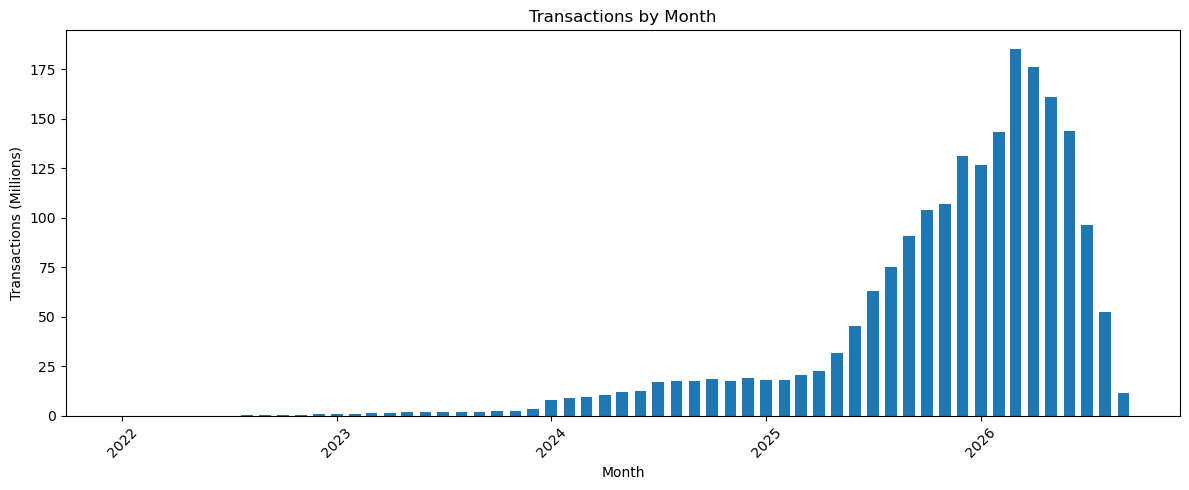

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_df["month"],
    monthly_df["transactions"] / 1e6,
    width=20
)

plt.title("Transactions by Month")
plt.xlabel("Month")
plt.ylabel("Transactions (Millions)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [42]:
cutoffs = []

for target in [70, 85]:
    closest = monthly_df.iloc[
        (monthly_df["cumulative_pct"] - target).abs().argmin()
    ]

    cutoffs.append({
        "Target %": target,
        "Month": closest["month"],
        "Cumulative %": round(closest["cumulative_pct"], 2)
    })

display(pd.DataFrame(cutoffs))

,Target %,Month,Cumulative %
0,70,2026-03-01,68.22
1,85,2026-05-01,84.93


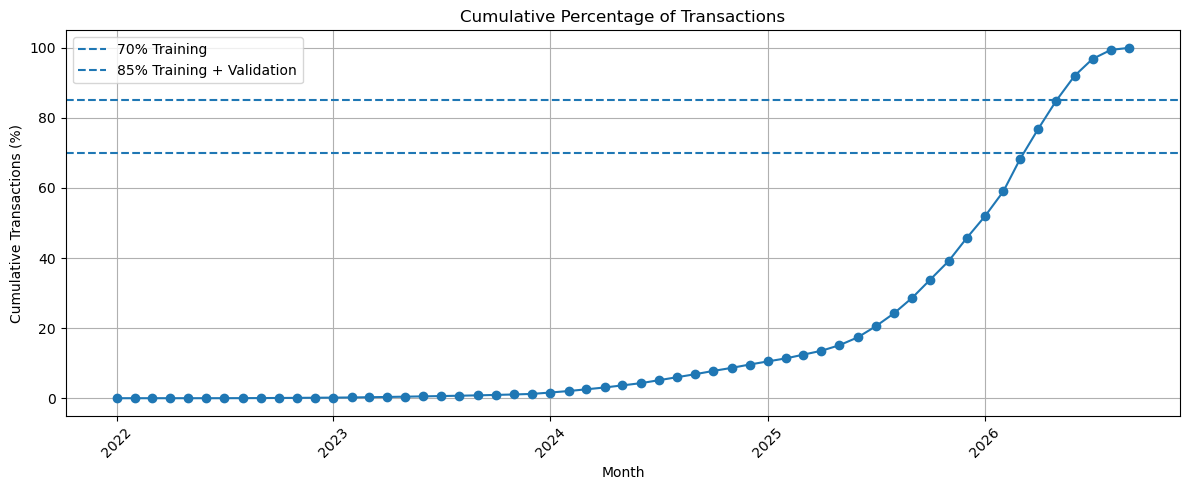

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["month"],
    monthly_df["cumulative_pct"],
    marker="o"
)

plt.axhline(70, linestyle="--", label="70% Training")
plt.axhline(85, linestyle="--", label="85% Training + Validation")

plt.title("Cumulative Percentage of Transactions")
plt.xlabel("Month")
plt.ylabel("Cumulative Transactions (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [44]:
new_split_counts = con.execute("""
SELECT
    CASE
        WHEN posted_date < '2026-04-01' THEN 'Training'
        WHEN posted_date < '2026-06-01' THEN 'Validation'
        ELSE 'Testing'
    END AS split,
    COUNT(*) AS transactions,
    COUNT(DISTINCT account_key) AS accounts
FROM read_parquet('/home/l6feng/teams/d12/UCSD - Data Share/ucsd_transactions_part_*.parquet')
GROUP BY split
""").df()

new_split_counts["percentage"] = (
    new_split_counts["transactions"]
    / new_split_counts["transactions"].sum() * 100
)

display(new_split_counts)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,split,transactions,accounts,percentage
0,Training,1376056621,1035348,68.218950
1,Testing,304015654,378719,15.071784
2,Validation,337045574,537851,16.709265


In [45]:
df400["posted_date"] = pd.to_datetime(df400["posted_date"])

def new_split(row):
    if row["split"] == "Testing B":
        return "Testing B"
    elif row["posted_date"] < pd.Timestamp("2026-04-01"):
        return "Training"
    elif row["posted_date"] < pd.Timestamp("2026-06-01"):
        return "Validation"
    else:
        return "Testing A"

df400["new_split"] = df400.apply(new_split, axis=1)

print("Old split:")
print(df400["split"].value_counts())

print("\nNew split:")
print(df400["new_split"].value_counts())

print("\nOld vs new:")
print(pd.crosstab(df400["split"], df400["new_split"]))

Old split:
split
Training      280
Validation     60
Testing A      30
Testing B      30
Name: count, dtype: int64

New split:
new_split
Training      309
Testing A      40
Testing B      30
Validation     21
Name: count, dtype: int64

Old vs new:
new_split   Testing A  Testing B  Training  Validation
split                                                 
Testing A          30          0         0           0
Testing B           0         30         0           0
Training            0          0       280           0
Validation         10          0        29          21


In [46]:
print("Current new split counts:")
print(df400["new_split"].value_counts())

print("\nUnique accounts in each new split:")
print(df400.groupby("new_split")["account_key"].nunique())

print("\nMissing labels:")
print(df400["Final Agreed Upon"].isna().sum())

Current new split counts:
new_split
Training      309
Testing A      40
Testing B      30
Validation     21
Name: count, dtype: int64

Unique accounts in each new split:
new_split
Testing A     13
Testing B      4
Training      16
Validation     9
Name: account_key, dtype: int64

Missing labels:
0


In [47]:
train_new = df400[df400["new_split"] == "Training"].sample(
    n=280, random_state=42
)

valid_new = df400[df400["new_split"] == "Validation"].copy()

test_a_new = df400[df400["new_split"] == "Testing A"].sample(
    n=30, random_state=42
)

test_b_new = df400[df400["new_split"] == "Testing B"].copy()

print("Training:", len(train_new))
print("Validation:", len(valid_new))
print("Testing A:", len(test_a_new))
print("Testing B:", len(test_b_new))

Training: 280
Validation: 21
Testing A: 30
Testing B: 30


In [48]:
print("Testing A accounts also in training:",
      len(set(test_a_new["account_key"]) & set(train_new["account_key"])))

print("Testing B accounts also in training:",
      len(set(test_b_new["account_key"]) & set(train_new["account_key"])))

Testing A accounts also in training: 12
Testing B accounts also in training: 0


In [50]:
train_pool = df400[df400["new_split"] == "Training"]

test_a_accounts = test_a_new["account_key"].unique()

required = (
    train_pool[train_pool["account_key"].isin(test_a_accounts)]
    .groupby("account_key")
    .sample(n=1, random_state=42)
)

remaining = train_pool.drop(index=required.index)

train_new = pd.concat([
    required,
    remaining.sample(n=280-len(required), random_state=42)
])

print("Training transactions:", len(train_new))

print("Testing A unique accounts:", test_a_new["account_key"].nunique())

print("Testing A accounts in training:",
      len(set(test_a_new["account_key"]) & set(train_new["account_key"])))

print("Missing accounts:",
      set(test_a_new["account_key"]) - set(train_new["account_key"]))

Training transactions: 280
Testing A unique accounts: 12
Testing A accounts in training: 12
Missing accounts: set()


In [51]:
cols = ["account_key", "posted_date", "memo", "amount", "credit_or_debit"]

validation_pool = selected_df[
    selected_df["account_key"].isin(seen_accounts) &
    (selected_df["posted_date"] >= "2026-04-01") &
    (selected_df["posted_date"] < "2026-06-01")
].drop_duplicates(subset=cols)

validation_pool = validation_pool.merge(
    df400[cols],
    on=cols,
    how="left",
    indicator=True
)

validation_pool = validation_pool[
    validation_pool["_merge"] == "left_only"
].drop(columns="_merge")

print("Available new validation transactions:", len(validation_pool))

new_validation39 = validation_pool.sample(
    n=39,
    random_state=42
).copy()

new_validation39["new_split"] = "Validation"
new_validation39["Final Agreed Upon"] = ""
new_validation39["Review Status"] = ""

print("New transactions selected:", len(new_validation39))

Available new validation transactions: 1779
New transactions selected: 39


In [52]:
new_validation39.to_csv(
    "/home/l6feng/private/fasttext_39_validation_to_label.csv",
    index=False
)

print("CSV saved successfully")
print("Transactions:", len(new_validation39))

CSV saved successfully
Transactions: 39


In [53]:
new39 = pd.read_csv(
    "/home/l6feng/private/fasttext_39_validation_labeled_proposed.csv"
)

valid_new = pd.concat(
    [valid_new, new39],
    ignore_index=True
)

print("Validation transactions:", len(valid_new))
print("Missing labels:", valid_new["Final Agreed Upon"].isna().sum())

Validation transactions: 60
Missing labels: 0


In [54]:
train_new = train_new.assign(new_split="Training")
valid_new = valid_new.assign(new_split="Validation")
test_a_new = test_a_new.assign(new_split="Testing A")
test_b_new = test_b_new.assign(new_split="Testing B")

df400_new = pd.concat(
    [train_new, valid_new, test_a_new, test_b_new],
    ignore_index=True
)

print("Total transactions:", len(df400_new))

print("\nTransactions by split:")
print(df400_new["new_split"].value_counts())

print("\nMissing labels:")
print(df400_new["Final Agreed Upon"].isna().sum())

Total transactions: 400

Transactions by split:
new_split
Training      280
Validation     60
Testing A      30
Testing B      30
Name: count, dtype: int64

Missing labels:
0


In [56]:
cols = ["account_key", "posted_date", "memo", "amount", "credit_or_debit"]

print("Duplicate transactions:", df400_new.duplicated(subset=cols).sum())

print("\nTesting A accounts missing from training:")
print(
    set(test_a_new["account_key"]) -
    set(train_new["account_key"])
)

print("\nTesting B accounts overlapping with training:")
print(
    set(test_b_new["account_key"]) &
    set(train_new["account_key"])
)

print("\nDate ranges:")
print(
    df400_new.groupby("new_split")["posted_date"]
    .agg(["min", "max"])
)

Duplicate transactions: 0

Testing A accounts missing from training:
set()

Testing B accounts overlapping with training:
set()

Date ranges:


TypeError: agg function failed [how->min,dtype->object]

In [57]:
df400_new["posted_date"] = pd.to_datetime(
    df400_new["posted_date"]
)

print(
    df400_new.groupby("new_split")["posted_date"]
    .agg(["min", "max"])
)

                  min        max
new_split                       
Testing A  2026-06-02 2026-09-14
Testing B  2026-07-01 2026-09-02
Training   2025-04-01 2026-03-30
Validation 2026-04-01 2026-05-30


In [58]:
import re

df400_new["label_id"] = (
    df400_new["Final Agreed Upon"]
    .str.lower()
    .apply(lambda x: re.sub(r"[^a-z0-9]+", "_", x).strip("_"))
)

df400_new["cleaned_memo"] = (
    df400_new["memo"]
    .fillna("")
    .str.lower()
    .str.split()
    .str.join(" ")
)

def save_fasttext(data, filename):
    with open(filename, "w") as f:
        for _, row in data.iterrows():
            if row["cleaned_memo"]:
                f.write(
                    "__label__" + row["label_id"] + " " +
                    row["cleaned_memo"] + "\n"
                )

save_fasttext(
    df400_new[df400_new["new_split"] == "Training"],
    "train_new.txt"
)

save_fasttext(
    df400_new[df400_new["new_split"] == "Validation"],
    "valid_new.txt"
)

save_fasttext(
    df400_new[df400_new["new_split"] == "Testing A"],
    "test_a_new.txt"
)

save_fasttext(
    df400_new[df400_new["new_split"] == "Testing B"],
    "test_b_new.txt"
)

print("New FastText files created.")

New FastText files created.


In [59]:
import fasttext
import pandas as pd

results_new = []

for epoch in [5, 25, 50, 100]:
    m = fasttext.train_supervised(
        input="train_new.txt",
        wordNgrams=2,
        epoch=epoch
    )

    _, train_acc, _ = m.test("train_new.txt")
    _, valid_acc, _ = m.test("valid_new.txt")

    results_new.append({
        "Epochs": epoch,
        "Training Accuracy": train_acc,
        "Validation Accuracy": valid_acc
    })

results_new_df = pd.DataFrame(results_new)

display(results_new_df)

Read 0M words
Number of words:  526
Number of labels: 19
Progress: 100.0% words/sec/thread:     682 lr:  0.000000 avg.loss:  2.956846 ETA:   0h 0m 0s
Read 0M words
Number of words:  526
Number of labels: 19
Progress: 100.0% words/sec/thread:    3022 lr:  0.000000 avg.loss:  2.595827 ETA:   0h 0m 0s
Read 0M words
Number of words:  526
Number of labels: 19
Progress: 100.0% words/sec/thread:    1770 lr:  0.000000 avg.loss:  1.774015 ETA:   0h 0m 0s
Read 0M words
Number of words:  526
Number of labels: 19
Progress: 100.0% words/sec/thread:    1783 lr:  0.000000 avg.loss:  1.456067 ETA:   0h 0m 0s


,Epochs,Training Accuracy,Validation Accuracy
0,5,0.246429,0.183333
1,25,0.603571,0.416667
2,50,0.935714,0.633333
3,100,0.964286,0.516667


In [60]:
model50_new = fasttext.train_supervised(
    input="train_new.txt",
    wordNgrams=2,
    epoch=50
)

model50_new.save_model("expense_new.bin")

print("Training:", model50_new.test("train_new.txt"))
print("Validation:", model50_new.test("valid_new.txt"))

Read 0M words
Number of words:  526
Number of labels: 19


Training: (280, 0.9071428571428571, 0.9071428571428571)
Validation: (60, 0.65, 0.65)


Progress: 100.0% words/sec/thread:    2015 lr:  0.000000 avg.loss:  1.948273 ETA:   0h 0m 0s


In [61]:
print("Testing A:", model50_new.test("test_a_new.txt"))
print("Testing B:", model50_new.test("test_b_new.txt"))

Testing A: (30, 0.6, 0.6)
Testing B: (30, 0.3, 0.3)


In [62]:
test_df_new = df400_new[
    df400_new["new_split"].isin(["Testing A", "Testing B"])
].copy()

pred_labels, scores = model50_new.predict(
    test_df_new["cleaned_memo"].tolist(),
    k=1
)

test_df_new["predicted"] = [
    labels[0].replace("__label__", "")
    for labels in pred_labels
]

test_df_new["actual"] = test_df_new["label_id"]
test_df_new["correct"] = (
    test_df_new["predicted"] == test_df_new["actual"]
)

print("Accuracy by testing set:")
print(
    test_df_new.groupby("new_split")["correct"]
    .agg(["sum", "count", "mean"])
)

print("\nClassification errors:")
print(
    test_df_new[~test_df_new["correct"]]
    .groupby(["new_split", "actual", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values(["new_split", "count"], ascending=[True, False])
    .to_string(index=False)
)

Accuracy by testing set:
           sum  count  mean
new_split                  
Testing A   18     30   0.6
Testing B    9     30   0.3

Classification errors:
new_split                      actual predicted  count
Testing A         finance_investments uncertain      2
Testing A                   groceries uncertain      2
Testing A             bills_utilities uncertain      1
Testing A                cash_out_atm uncertain      1
Testing A        debt_credit_payments  shopping      1
Testing A        debt_credit_payments transfers      1
Testing A             income_deposits  shopping      1
Testing A subscriptions_entertainment  shopping      1
Testing A subscriptions_entertainment uncertain      1
Testing A                   uncertain transfers      1
Testing B             income_deposits uncertain      4
Testing B                  food_drink transfers      2
Testing B                    shopping transfers      2
Testing B subscriptions_entertainment uncertain      2
Testing B     